# Who&When Pro: Error EDA (text split)

Dataset: Who&When Pro (Liu et al., arXiv 2607.09996), `Leoxx/whowhen_pro`, **text split only** (6,257 traces; image/GUI/video not used).
Tables come from `eda/00_build_tables.py` (`eda/outputs/tables/traces.parquet`, `steps.parquet`).

**Read this first**
- Traces are **synthetic**: a successful trajectory is replayed to step t, a bad action is injected, and the run is kept only if it then failed. Mode frequencies reflect the sampling design and failure filter, **not** how often real agents make each error. Every distribution below should be read with that caveat.
- Released labels are only **agent, step, mode** (step is given as `step`, `round`/`position` or `stage` depending on the framework; kept as released).
- Not in the release: backbone model (`NA`), seed trace id (we use `seed_group` = hash(framework, task query) as a proxy), injection position (derived), task category (looked up from the paper's figure), modality (constant: text).
- Counts are shown with percentages; cells with n < 30 are flagged low-support (`*`).
- Part B (LLM detectability: hit rates, confusion matrices) needs model runs and is **not** part of this notebook.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "eda").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
TAB = ROOT / "eda/outputs/tables"; FIG = ROOT / "eda/outputs/figures"
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

t = pd.read_parquet(TAB / "traces.parquet")
s = pd.read_parquet(TAB / "steps.parquet")
tax = pd.read_csv(TAB / "taxonomy_dataset.csv")
MIN_N = 30
FAM_ORDER = ["Perception","Reasoning","Planning","Action","Verification","Coordination"]
MODE_ORDER = tax["mode"].tolist()

# error agent: label agent, else first of agents list (debate/dylan), else single-agent
def err_agent(r):
    if pd.notna(r.gt_agent): return r.gt_agent
    if pd.notna(r.gt_agents): return json.loads(r.gt_agents)[0] if len(json.loads(r.gt_agents)) else "NA"
    return "NA (single-agent)"
t["error_agent"] = t.apply(err_agent, axis=1)
t["n_error_agents"] = t.gt_agents.map(lambda x: len(json.loads(x)) if pd.notna(x) else (0))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

def heat(ct, title, name, fmt="d", cmap="viridis", figsize=None, annot=True, vmax=None):
    figsize = figsize or (max(7, 0.6*ct.shape[1]+3), max(3, 0.45*ct.shape[0]+1.5))
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(ct, annot=annot, fmt=fmt, cmap=cmap, ax=ax, cbar=True, linewidths=.4, vmax=vmax)
    ax.set_title(title); fig.tight_layout(); save(fig, name)

def row_norm(ct):
    n = ct.sum(1)
    pct = ct.div(n, axis=0)*100
    return pct, n

## 0. Overview and sanity checks against the paper

In [2]:
print(f"traces: {len(t):,}   steps rows: {len(s):,}")
overview = pd.DataFrame({
    "this data (text split)": [len(t), t.benchmark.nunique(), t.task_category.nunique(), t.framework.nunique(), t.modality.nunique(), t.gt_mode.nunique(), round(t.n_steps.mean(),2)],
    "paper (all modalities)": [12326, 26, 9, 15, 3, 18, 7.5]},
    index=["traces","benchmarks","task categories","frameworks","modalities","error modes","avg steps/trace"])
display(overview)
print("Taxonomy in the dataset has", len(tax), "modes (README/taxonomy.yaml); the paper text says 18. Modes present in text split:", t.gt_mode.nunique())
print("Absent from text split:", sorted(set(MODE_ORDER) - set(t.gt_mode)))
display(tax)

traces: 6,257   steps rows: 44,212


,this data (text split),paper (all modalities)
traces,6257.00,12326.0
benchmarks,16.00,26.0
task categories,5.00,9.0
frameworks,8.00,15.0
modalities,1.00,3.0
error modes,14.00,18.0
avg steps/trace,5.77,7.5


Taxonomy in the dataset has 17 modes (README/taxonomy.yaml); the paper text says 18. Modes present in text split: 14
Absent from text split: ['P.1', 'P.2', 'PL.2']


,mode,name,family
0,P.1,Visual misidentification,Perception
1,P.2,Spatial/grounding error,Perception
2,R.1,Hallucination,Reasoning
3,R.2,Reasoning error,Reasoning
4,R.3,Numerical/calculation error,Reasoning
5,R.4,Task misunderstanding,Reasoning
6,PL.1,Ineffective Planning,Planning
7,PL.2,Goal drift,Planning
8,A.1,Tool parameter/invocation error,Action
9,A.2,Output format/syntax error,Action


In [3]:
# label shape per framework: which label coordinates are populated
lab = t.groupby("framework").agg(n=("id","size"),
    agent=("gt_agent", lambda x: x.notna().mean()), agents_list=("gt_agents", lambda x: x.notna().mean()),
    step=("gt_step", lambda x: x.notna().mean()), round=("gt_round", lambda x: x.notna().mean()),
    position=("gt_position", lambda x: x.notna().mean()), stage=("gt_stage", lambda x: x.notna().mean()),
    topology=("topology","first"), position_unit=("step_position_unit","first")).round(2)
display(lab)
lab.to_csv(TAB/"A0_label_shape_by_framework.csv")
print("Injection position located for", t.injection_pos_rel.notna().sum(), "of", len(t), "traces")
print("Gold answer missing:", t.gold_answer.isna().mean().round(3), " by framework:"); display(t.gold_answer.isna().groupby(t.framework).mean().round(2).to_frame("missing"))

,n,agent,agents_list,step,round,position,stage,topology,position_unit
framework,,,,,,,,,
alfagent,311,0.0,0.0,1.0,0.0,0.0,0.0,single-agent,action step
debate,445,0.0,1.0,0.0,1.0,0.0,0.0,multi-agent,round
dylan,152,0.0,1.0,0.0,1.0,0.0,0.0,multi-agent,round
macnet,261,1.0,0.0,0.0,1.0,1.0,0.0,multi-agent,agent turn
magentic-one,811,1.0,0.0,1.0,0.0,0.0,0.0,multi-agent,agent turn
mathchat,920,1.0,0.0,0.0,1.0,1.0,0.0,multi-agent,agent turn
metagpt,81,1.0,0.0,0.0,0.0,0.0,1.0,multi-agent,agent turn
smolagents,3276,0.0,0.0,1.0,0.0,0.0,0.0,single-agent,planning/action step


Injection position located for 6253 of 6257 traces
Gold answer missing: 0.05  by framework:


,missing
framework,
alfagent,1.0
debate,0.0
dylan,0.0
macnet,0.0
magentic-one,0.0
mathchat,0.0
metagpt,0.0
smolagents,0.0


## A1. Mode and family distribution

,name,family,n,pct,low_support
mode,,,,,
P.1,Visual misidentification,Perception,0,0.00,*
P.2,Spatial/grounding error,Perception,0,0.00,*
R.1,Hallucination,Reasoning,621,9.92,
R.2,Reasoning error,Reasoning,1089,17.40,
R.3,Numerical/calculation error,Reasoning,739,11.81,
R.4,Task misunderstanding,Reasoning,1120,17.90,
PL.1,Ineffective Planning,Planning,90,1.44,
PL.2,Goal drift,Planning,0,0.00,*
A.1,Tool parameter/invocation error,Action,31,0.50,


,n,pct
family,,
Perception,0,0.00
Reasoning,3569,57.04
Planning,90,1.44
Action,1578,25.22
Verification,614,9.81
Coordination,406,6.49


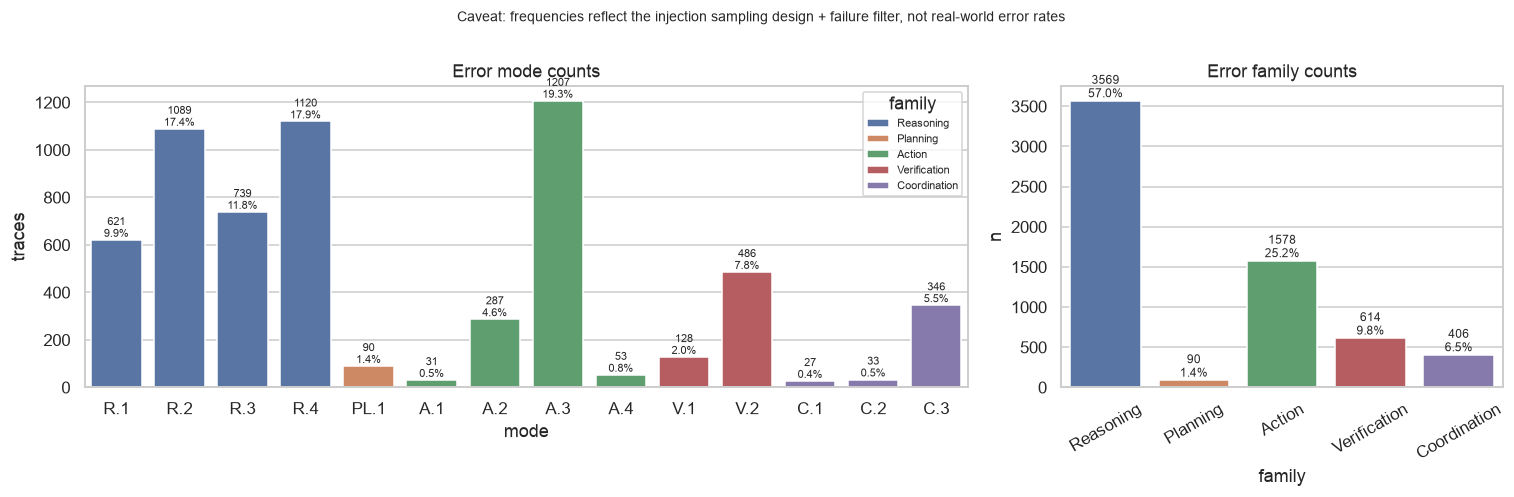

Chi-square vs uniform over 14 observed modes: chi2=5596, p=0; entropy=3.13 bits (uniform max 3.81); top-3 modes cover 54.6%


In [4]:
m = t.gt_mode.value_counts().reindex(MODE_ORDER).fillna(0).astype(int).rename("n").to_frame()
m["pct"] = (m.n/len(t)*100).round(2); m = tax.set_index("mode").join(m)
m["low_support"] = np.where((m.n<MIN_N), "*", "")
display(m); m.to_csv(TAB/"A1_mode_counts.csv")
f = t.family.value_counts().reindex(FAM_ORDER).fillna(0).astype(int).rename("n").to_frame(); f["pct"]=(f.n/len(t)*100).round(2)
display(f); f.to_csv(TAB/"A1_family_counts.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios":[2,1]})
mm = m[m.n>0]
sns.barplot(x=mm.index, y=mm.n, hue=mm.family, dodge=False, ax=ax[0], palette="deep")
for i,(k,r) in enumerate(mm.iterrows()): ax[0].text(i, r.n, f"{int(r.n)}\n{r.pct:.1f}%", ha="center", va="bottom", fontsize=7)
ax[0].set_title("Error mode counts"); ax[0].set_xlabel("mode"); ax[0].set_ylabel("traces"); ax[0].legend(title="family", fontsize=7)
ff = f[f.n>0]; sns.barplot(x=ff.index, y=ff.n, ax=ax[1], palette="deep")
for i,(k,r) in enumerate(ff.iterrows()): ax[1].text(i, r.n, f"{int(r.n)}\n{r.pct:.1f}%", ha="center", va="bottom", fontsize=8)
ax[1].set_title("Error family counts"); ax[1].tick_params(axis="x", rotation=30)
fig.suptitle("Caveat: frequencies reflect the injection sampling design + failure filter, not real-world error rates", fontsize=9, y=1.0)
fig.tight_layout(); save(fig, "A1_mode_family_distribution")

k = (m.n>0).sum(); p = m.n[m.n>0]/m.n.sum()
chi2, pv = stats.chisquare(m.n[m.n>0])
H = -(p*np.log2(p)).sum()
print(f"Chi-square vs uniform over {k} observed modes: chi2={chi2:.0f}, p={pv:.2g}; entropy={H:.2f} bits (uniform max {np.log2(k):.2f}); top-3 modes cover {p.nlargest(3).sum()*100:.1f}%")

## A2. Injection position (relative = injected step / number of steps)

n with position: 6253


,n,pct
injection_pos_rel,,
0-20%,319,5.1
20-40%,568,9.1
40-60%,974,15.6
60-80%,1072,17.1
80-100%,3320,53.1


share in the 40-80% range: 32.7%  (paper: 64%, over all modalities)


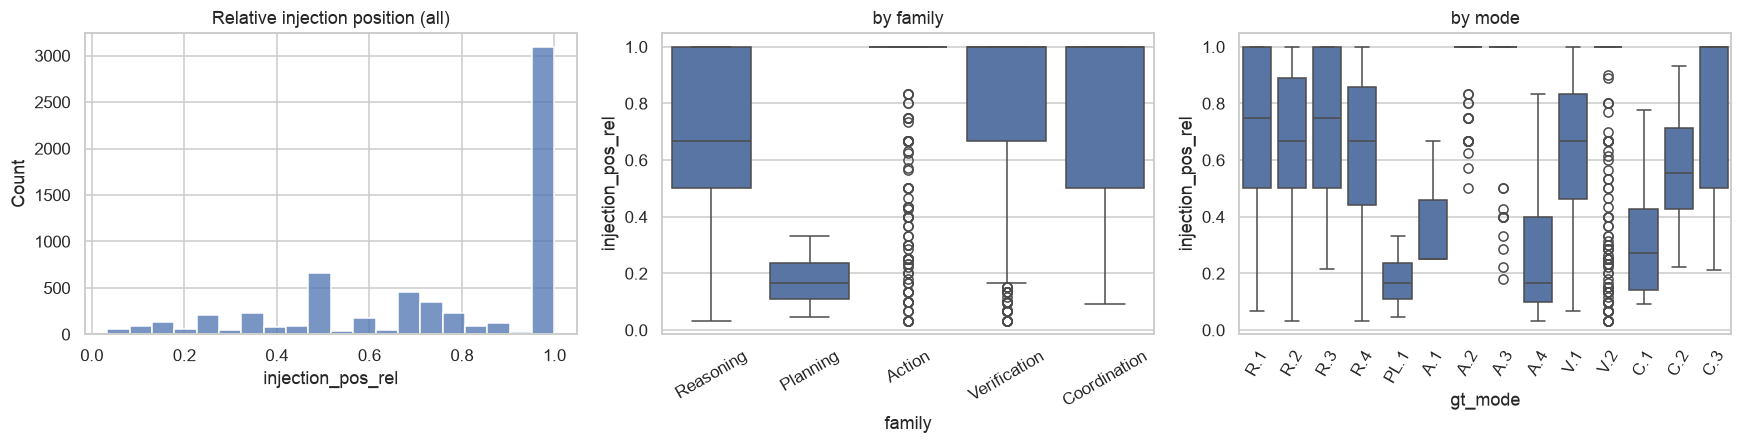

,count,mean,median
family,,,
Reasoning,3567,0.683,0.667
Planning,90,0.184,0.167
Action,1578,0.954,1.000
Verification,612,0.819,1.000
Coordination,406,0.766,1.000


Frameworks differ in position granularity (debate/dylan = round level), so check within framework too:


framework,alfagent,debate,dylan,macnet,magentic-one,mathchat,metagpt,smolagents
family,,,,,,,,
Reasoning,0.20,0.5,0.67,0.25,0.80,1.0,0.33,0.71
Planning,NaN,NaN,NaN,NaN,NaN,NaN,0.33,0.14
Action,0.17,NaN,NaN,0.25,1.00,NaN,0.67,1.00
Verification,0.30,NaN,NaN,0.25,1.00,NaN,NaN,1.00
Coordination,NaN,1.0,0.67,0.50,0.56,NaN,NaN,NaN


Planning (median 0.17, n=90) vs Verification (median 1.00, n=612): MWU p=4.8e-49
Planning (median 0.17, n=90) vs Reasoning (median 0.67, n=3567): MWU p=7.4e-50
Verification (median 1.00, n=612) vs Reasoning (median 0.67, n=3567): MWU p=1.8e-41


In [5]:
d = t.dropna(subset=["injection_pos_rel"]).copy()
print("n with position:", len(d))
bins = pd.cut(d.injection_pos_rel, [0,.2,.4,.6,.8,1.0], labels=["0-20%","20-40%","40-60%","60-80%","80-100%"], include_lowest=True)
bt = bins.value_counts().sort_index().to_frame("n"); bt["pct"]=(bt.n/bt.n.sum()*100).round(1); display(bt)
print(f"share in the 40-80% range: {((d.injection_pos_rel>0.4)&(d.injection_pos_rel<=0.8)).mean()*100:.1f}%  (paper: 64%, over all modalities)")
bt.to_csv(TAB/"A2_position_bins.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(d.injection_pos_rel, bins=20, ax=ax[0]); ax[0].set_title("Relative injection position (all)")
order = [x for x in FAM_ORDER if x in set(d.family)]
sns.boxplot(data=d, x="family", y="injection_pos_rel", order=order, ax=ax[1]); ax[1].set_title("by family"); ax[1].tick_params(axis="x", rotation=30)
mo = [x for x in MODE_ORDER if x in set(d.gt_mode)]
sns.boxplot(data=d, x="gt_mode", y="injection_pos_rel", order=mo, ax=ax[2]); ax[2].set_title("by mode"); ax[2].tick_params(axis="x", rotation=60)
fig.tight_layout(); save(fig, "A2_injection_position")

g = d.groupby("family").injection_pos_rel.agg(["count","mean","median"]).round(3).reindex(order); display(g); g.to_csv(TAB/"A2_position_by_family.csv")
print("Frameworks differ in position granularity (debate/dylan = round level), so check within framework too:")
gf = d.pivot_table(index="family", columns="framework", values="injection_pos_rel", aggfunc="median").round(2).reindex(order); display(gf)
for a,b in [("Planning","Verification"),("Planning","Reasoning"),("Verification","Reasoning")]:
    x, y = d[d.family==a].injection_pos_rel, d[d.family==b].injection_pos_rel
    if len(x)>=MIN_N and len(y)>=MIN_N:
        u = stats.mannwhitneyu(x, y); print(f"{a} (median {x.median():.2f}, n={len(x)}) vs {b} (median {y.median():.2f}, n={len(y)}): MWU p={u.pvalue:.2g}")

In [6]:
# the paper says planning errors are early, verification late. Re-test inside the largest framework to remove framework mixing
for fw in ["smolagents","magentic-one","mathchat"]:
    dd = d[d.framework==fw]; print(fw, dd.groupby("family").injection_pos_rel.agg(["count","median"]).round(2).to_dict("index"))

smolagents {'Action': {'count': 1429, 'median': 1.0}, 'Planning': {'count': 73, 'median': 0.14}, 'Reasoning': {'count': 1510, 'median': 0.71}, 'Verification': {'count': 260, 'median': 1.0}}
magentic-one {'Action': {'count': 59, 'median': 1.0}, 'Coordination': {'count': 86, 'median': 0.56}, 'Reasoning': {'count': 422, 'median': 0.8}, 'Verification': {'count': 244, 'median': 1.0}}
mathchat {'Reasoning': {'count': 920, 'median': 1.0}}


## A3. Absolute step index and trace length

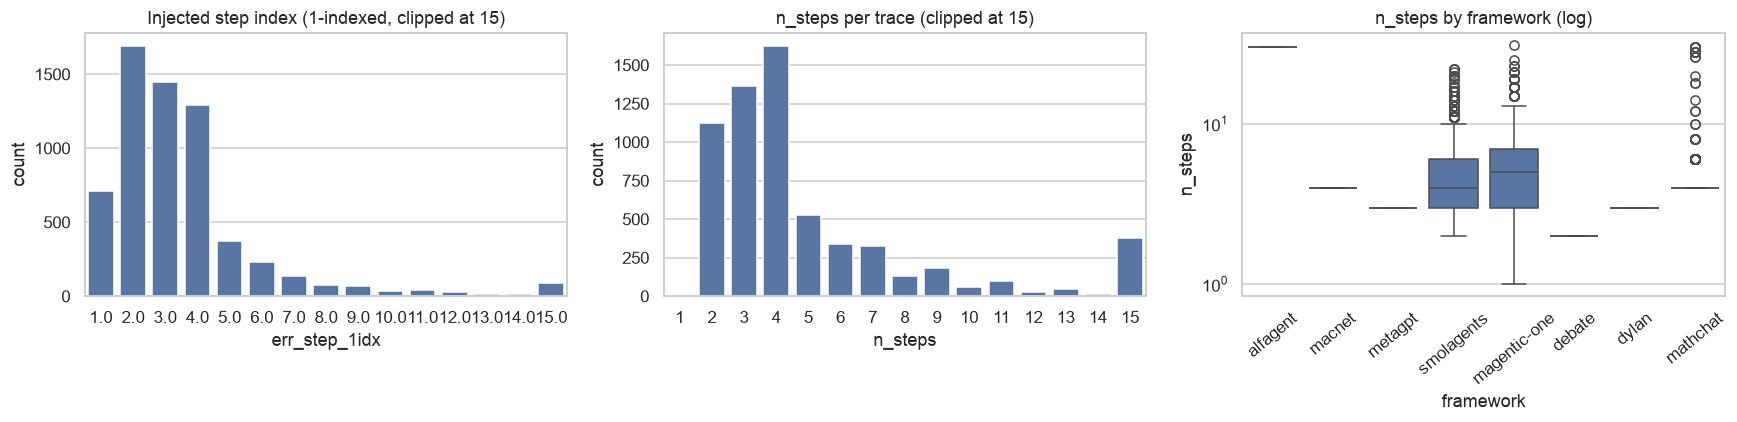

{'error at step 1': '711 (11.4%)', 'error at step 2': '1693 (27.1%)', 'error at step 3': '1448 (23.2%)'}
traces with n_steps<=3 (localization nearly trivial): 2489 (39.8%)  n_steps<=2: 1124


,n,mean_steps,median_steps,short_le3,mean_words
framework,,,,,
alfagent,311,30.00,30.0,0.00,1054.73
debate,445,2.00,2.0,1.00,2504.31
dylan,152,3.00,3.0,1.00,5236.03
macnet,261,4.00,4.0,0.00,1844.64
magentic-one,811,6.10,5.0,0.42,818.66
mathchat,920,4.62,4.0,0.00,886.68
metagpt,81,3.00,3.0,1.00,2261.84
smolagents,3276,4.56,4.0,0.45,1132.81


Words per trace: median 807.0  p90 3065.0000000000027  p99 6377.319999999999


In [7]:
d["err_step_1idx"] = d.inj_unit_idx + 1
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x=d.err_step_1idx.clip(upper=15), ax=ax[0]); ax[0].set_title("Injected step index (1-indexed, clipped at 15)")
sns.countplot(x=t.n_steps.clip(upper=15), ax=ax[1]); ax[1].set_title("n_steps per trace (clipped at 15)")
sns.boxplot(data=t, x="framework", y="n_steps", ax=ax[2]); ax[2].set_yscale("log"); ax[2].tick_params(axis="x", rotation=40); ax[2].set_title("n_steps by framework (log)")
fig.tight_layout(); save(fig, "A3_step_index_and_length")
tot = len(d)
print({f"error at step {i}": f"{(d.err_step_1idx==i).sum()} ({(d.err_step_1idx==i).mean()*100:.1f}%)" for i in (1,2,3)})
print("traces with n_steps<=3 (localization nearly trivial):", (t.n_steps<=3).sum(), f"({(t.n_steps<=3).mean()*100:.1f}%)", " n_steps<=2:", (t.n_steps<=2).sum())
st = t.groupby("framework").agg(n=("id","size"), mean_steps=("n_steps","mean"), median_steps=("n_steps","median"), short_le3=("n_steps", lambda x:(x<=3).mean()), mean_words=("n_words","mean")).round(2)
display(st); st.to_csv(TAB/"A3_length_by_framework.csv")
print("Words per trace: median", t.n_words.median(), " p90", t.n_words.quantile(.9), " p99", t.n_words.quantile(.99))

## A4. Task category x mode
Row-normalized share (mode given task category) with counts, `*` marks rows with n < 30.

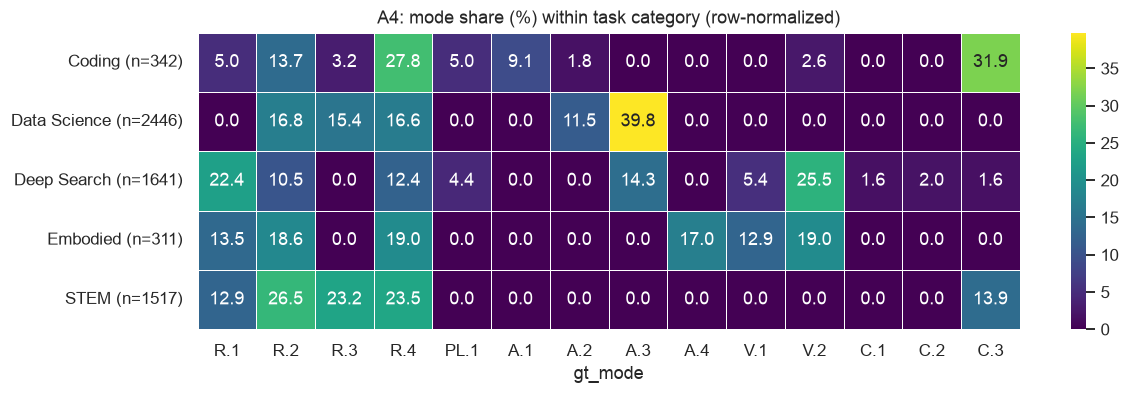

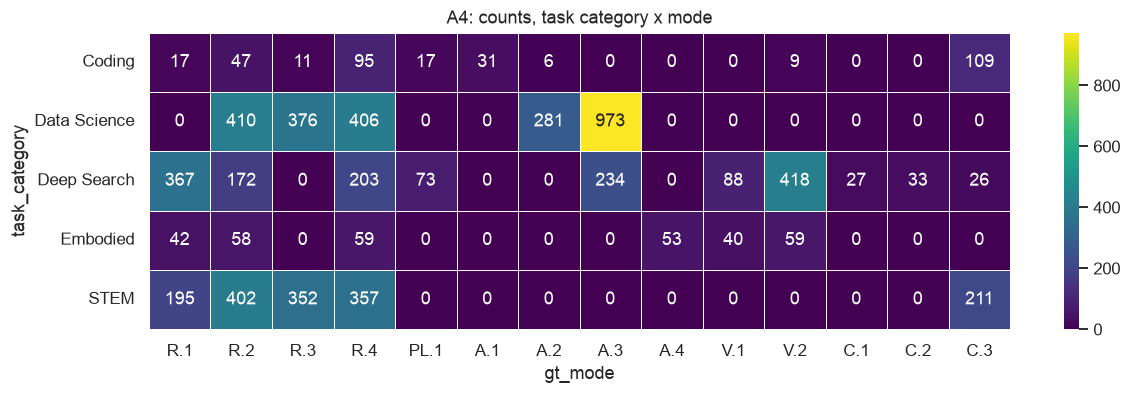

35 empty cells of 70. Modes with zero count in every category (not shown): ['P.1', 'P.2', 'PL.2']
Empty cells: [('Coding', 'A.3'), ('Coding', 'A.4'), ('Coding', 'V.1'), ('Coding', 'C.1'), ('Coding', 'C.2'), ('Data Science', 'R.1'), ('Data Science', 'PL.1'), ('Data Science', 'A.1'), ('Data Science', 'A.4'), ('Data Science', 'V.1'), ('Data Science', 'V.2'), ('Data Science', 'C.1'), ('Data Science', 'C.2'), ('Data Science', 'C.3'), ('Deep Search', 'R.3'), ('Deep Search', 'A.1'), ('Deep Search', 'A.2'), ('Deep Search', 'A.4'), ('Embodied', 'R.3'), ('Embodied', 'PL.1'), ('Embodied', 'A.1'), ('Embodied', 'A.2'), ('Embodied', 'A.3'), ('Embodied', 'C.1'), ('Embodied', 'C.2'), ('Embodied', 'C.3'), ('STEM', 'PL.1'), ('STEM', 'A.1'), ('STEM', 'A.2'), ('STEM', 'A.3'), ('STEM', 'A.4'), ('STEM', 'V.1'), ('STEM', 'V.2'), ('STEM', 'C.1'), ('STEM', 'C.2')]


In [8]:
def ct_pair(row, col, name, rows_order=None, cols=MODE_ORDER):
    ct = pd.crosstab(t[row], t[col]); ct = ct.reindex(columns=[c for c in cols if c in ct.columns])
    if rows_order: ct = ct.reindex([r for r in rows_order if r in ct.index])
    pct, n = row_norm(ct)
    ct.to_csv(TAB/f"{name}_counts.csv"); pct.round(2).to_csv(TAB/f"{name}_rownorm_pct.csv")
    return ct, pct, n

ct, pct, n = ct_pair("task_category", "gt_mode", "A4_category_x_mode")
pct.index = [f"{i} (n={n[i]})" for i in pct.index]
heat(pct.round(1), "A4: mode share (%) within task category (row-normalized)", "A4_category_x_mode_rownorm", fmt=".1f")
heat(ct, "A4: counts, task category x mode", "A4_category_x_mode_counts")
empty = [(r,c) for r in ct.index for c in ct.columns if ct.loc[r,c]==0]
print(f"{len(empty)} empty cells of {ct.size}. Modes with zero count in every category (not shown): {sorted(set(MODE_ORDER)-set(t.gt_mode))}")
print("Empty cells:", empty[:40])

## A5. Source benchmark x mode

low-support benchmarks (n<30): ['humaneval']


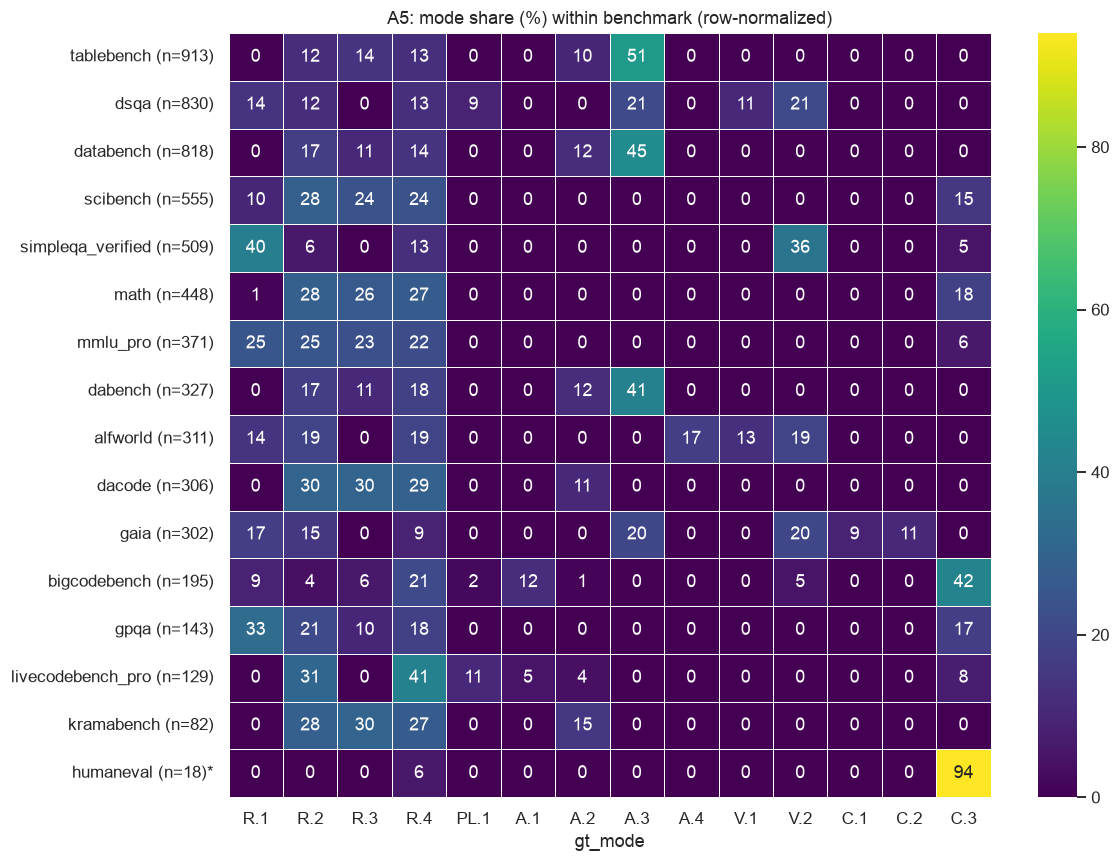

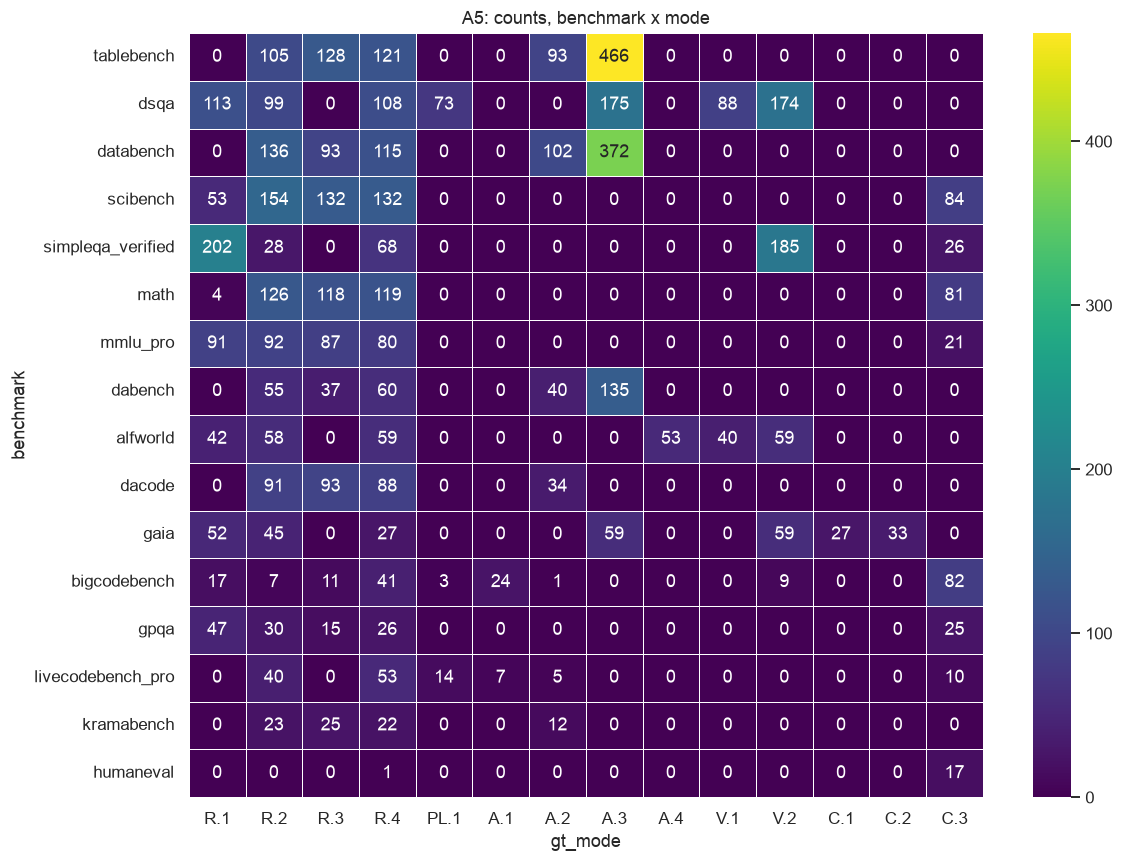

In [9]:
ct, pct, n = ct_pair("benchmark", "gt_mode", "A5_benchmark_x_mode")
order = n.sort_values(ascending=False).index
ct = ct.loc[order]; pct = pct.loc[order]
lowrows = [b for b in ct.index if n[b] < MIN_N]; print("low-support benchmarks (n<30):", lowrows)
pp = pct.copy(); pp.index = [f"{i} (n={n[i]}){'*' if n[i]<MIN_N else ''}" for i in pp.index]
heat(pp.round(0), "A5: mode share (%) within benchmark (row-normalized)", "A5_benchmark_x_mode_rownorm", fmt=".0f", figsize=(11, 8))
heat(ct, "A5: counts, benchmark x mode", "A5_benchmark_x_mode_counts", figsize=(11, 8))

## A6. Framework x mode (with framework trace share)

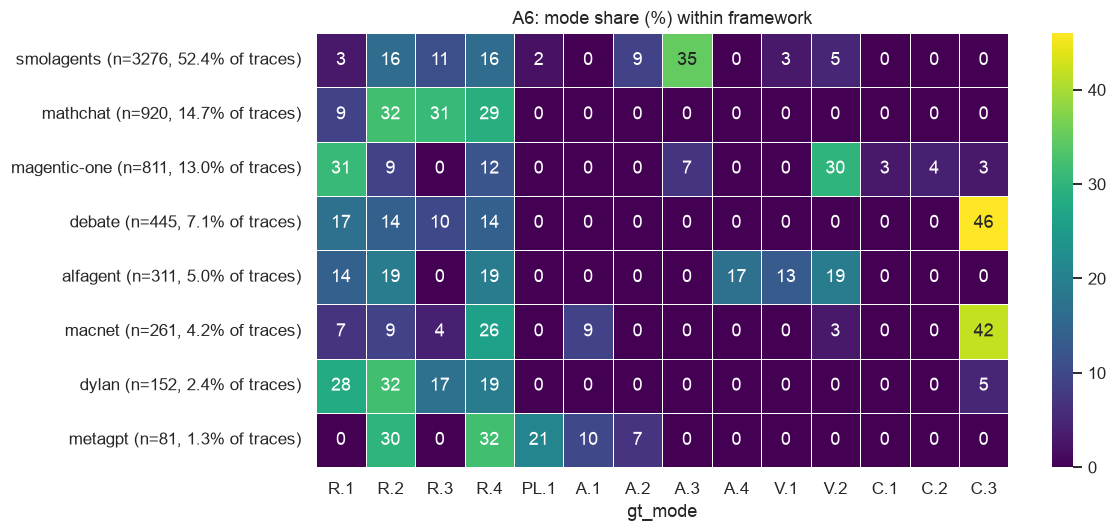

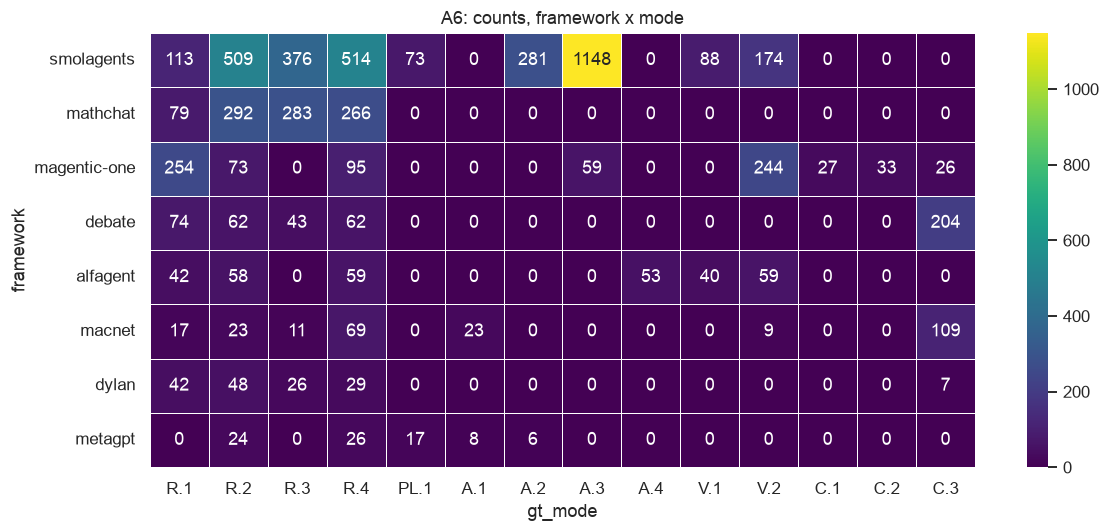

family,Reasoning,Planning,Action,Verification,Coordination
framework,,,,,
smolagents,1512,73,1429,262,0
mathchat,920,0,0,0,0
magentic-one,422,0,59,244,86
debate,241,0,0,0,204
alfagent,159,0,53,99,0
macnet,120,0,23,9,109
dylan,145,0,0,0,7
metagpt,50,17,14,0,0


Modes dominated by one framework (share of that mode's traces):


,top_framework,top_share_pct,n_mode
gt_mode,,,
R.1,magentic-one,40.9,621
R.2,smolagents,46.7,1089
R.3,smolagents,50.9,739
R.4,smolagents,45.9,1120
PL.1,smolagents,81.1,90
A.1,macnet,74.2,31
A.2,smolagents,97.9,287
A.3,smolagents,95.1,1207
A.4,alfagent,100.0,53


In [10]:
ct, pct, n = ct_pair("framework", "gt_mode", "A6_framework_x_mode")
share = (n/len(t)*100).round(1)
order = n.sort_values(ascending=False).index
pp = pct.loc[order].copy(); pp.index = [f"{i} (n={n[i]}, {share[i]}% of traces){'*' if n[i]<MIN_N else ''}" for i in pp.index]
heat(pp.round(0), "A6: mode share (%) within framework", "A6_framework_x_mode_rownorm", fmt=".0f", figsize=(11, 5))
heat(ct.loc[order], "A6: counts, framework x mode", "A6_framework_x_mode_counts", figsize=(11, 5))
cf = pd.crosstab(t.framework, t.family).reindex(columns=[c for c in FAM_ORDER if c in set(t.family)]).loc[order]
display(cf); cf.to_csv(TAB/"A6_framework_x_family_counts.csv")
print("Modes dominated by one framework (share of that mode's traces):")
col = ct.div(ct.sum(0), axis=1)*100
dom = pd.DataFrame({"top_framework": col.idxmax(), "top_share_pct": col.max().round(1), "n_mode": ct.sum(0)}); display(dom)

## A7. Modality and topology
Modality is constant (text) in this split, so the modality x mode analysis reduces to topology (single vs multi-agent).

{'text': 6257}


gt_mode,R.1,R.2,R.3,R.4,PL.1,A.1,A.2,A.3,A.4,V.1,V.2,C.1,C.2,C.3
topology,,,,,,,,,,,,,,
multi-agent,466,522,363,547,17,31,6,59,0,0,253,27,33,346
single-agent,155,567,376,573,73,0,281,1148,53,128,233,0,0,0


gt_mode,R.1,R.2,R.3,R.4,PL.1,A.1,A.2,A.3,A.4,V.1,V.2,C.1,C.2,C.3
topology,,,,,,,,,,,,,,
multi-agent,17.5,19.6,13.6,20.5,0.6,1.2,0.2,2.2,0.0,0.0,9.5,1.0,1.2,13.0
single-agent,4.3,15.8,10.5,16.0,2.0,0.0,7.8,32.0,1.5,3.6,6.5,0.0,0.0,0.0


family,Reasoning,Planning,Action,Verification,Coordination
topology,,,,,
multi-agent,1898,17,96,253,406
single-agent,1671,73,1482,361,0


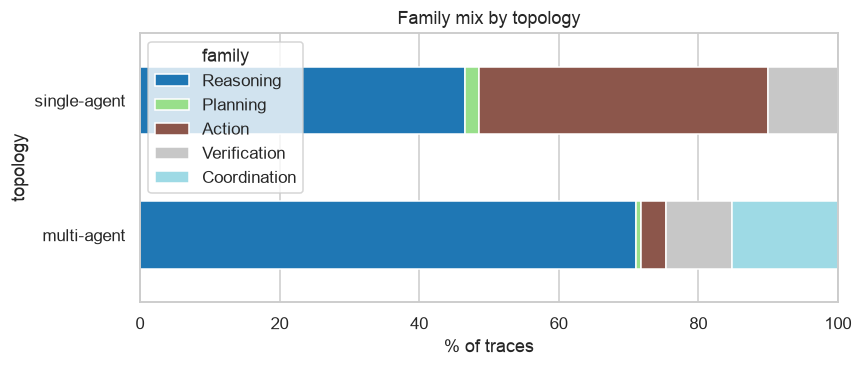

In [11]:
print(t.modality.value_counts().to_dict())
ct, pct, n = ct_pair("topology", "gt_mode", "A7_topology_x_mode")
display(ct); display(pct.round(1))
cf = pd.crosstab(t.topology, t.family).reindex(columns=[c for c in FAM_ORDER if c in set(t.family)])
display(cf); cf.to_csv(TAB/"A7_topology_x_family_counts.csv")
fig, ax = plt.subplots(figsize=(8,3.5)); (cf.div(cf.sum(1), axis=0)*100).plot(kind="barh", stacked=True, ax=ax, colormap="tab20"); ax.set_xlabel("% of traces"); ax.set_title("Family mix by topology")
fig.tight_layout(); save(fig, "A7_topology_family")

## A8. Topology and error agent roles
Coordination modes (C.1-C.3) should only appear in multi-agent traces; and which agent roles receive the injected error?

Coordination traces by topology: {'multi-agent': 406}
Single-agent traces with a C.* label: 0


,n,top_mode,top_mode_share
fw_agent,,,
mathchat:assistant,920,R.2,0.32
magentic-one:orchestrator,636,V.2,0.34
debate:agent_2,271,C.3,0.53
debate:agent_1,195,C.3,0.64
debate:agent_0,183,C.3,0.76
macnet:node_0,152,R.4,0.45
macnet:node_1,109,C.3,1.00
magentic-one:websurfer,93,R.2,0.34
magentic-one:coder,69,R.1,0.45


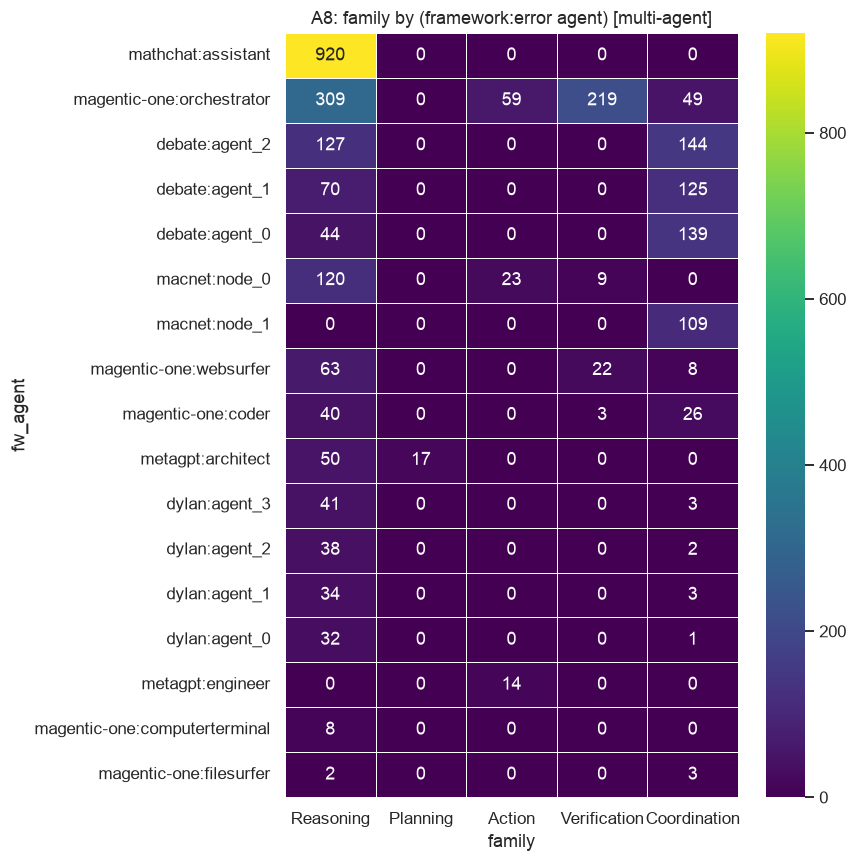

family,Action,Coordination,Planning,Reasoning,Verification
role_type,,,,,
debater/other,0,417,0,386,0
downstream node,0,109,0,0,0
executor/solver,14,37,0,1033,25
orchestrator/planner,59,49,17,359,219
source node,23,0,0,120,9


In [12]:
coord = t[t.family=="Coordination"]
print("Coordination traces by topology:", coord.topology.value_counts().to_dict())
print("Single-agent traces with a C.* label:", int(((t.topology=="single-agent")&(t.family=="Coordination")).sum()))

multi = t[t.topology=="multi-agent"].copy()
# debate/dylan can name several agents; explode so every named agent counts once
multi["agent_list"] = multi.apply(lambda r: json.loads(r.gt_agents) if pd.notna(r.gt_agents) else [r.error_agent], axis=1)
ex = multi.explode("agent_list").rename(columns={"agent_list":"agent_role"}).reset_index(drop=True)
ex["fw_agent"] = ex.framework + ":" + ex.agent_role.astype(str)
ar = ex.groupby("fw_agent").agg(n=("id","nunique"), top_mode=("gt_mode", lambda x:x.value_counts().index[0]), top_mode_share=("gt_mode", lambda x:x.value_counts(normalize=True).iloc[0])).sort_values("n", ascending=False).round(2)
display(ar); ar.to_csv(TAB/"A8_error_agent_by_framework.csv")
role_ct = pd.crosstab(ex.fw_agent, ex.family).reindex(columns=[c for c in FAM_ORDER if c in set(ex.family)])
role_ct = role_ct.loc[ar.index]
heat(role_ct, "A8: family by (framework:error agent) [multi-agent]", "A8_agent_x_family", figsize=(8, 8))
# orchestrator/planner vs executor
role_type = {"orchestrator":"orchestrator/planner","architect":"orchestrator/planner","node_0":"source node","node_1":"downstream node","assistant":"executor/solver","engineer":"executor/solver","coder":"executor/solver","websurfer":"executor/solver","filesurfer":"executor/solver","computerterminal":"executor/solver","reviewer":"reviewer"}
ex["role_type"] = ex.agent_role.map(role_type).fillna("debater/other")
display(pd.crosstab(ex.role_type, ex.family))

## A9. Backbone model
Backbone is **not recorded** in the released traces (paper App. G.2 says it should be in the metadata, but `extras` has no such field), so this cannot be analysed. Placeholder to make the gap explicit:

In [13]:
print(t.backbone.value_counts().to_dict())
print("extras keys that exist (see schema notes): agents, topology, eval_status, eval_error_preview, final_answer, termination, post_injection_turns")

{'NA': 6257}
extras keys that exist (see schema notes): agents, topology, eval_status, eval_error_preview, final_answer, termination, post_injection_turns


## A10. Confounding check
Framework, benchmark/task category and topology are nested. Question: which factor still predicts the error family/mode after controlling for the others?
We compare **cross-validated log-loss** (5-fold, grouped by `seed_group` so repeated seeds do not leak) of multinomial logistic models on one-hot predictors vs. a prior-only baseline.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.dummy import DummyClassifier

def cvll(cols, target, data):
    y = data[target].values; groups = data.seed_group.values
    gkf = GroupKFold(5)
    if cols:
        X = OneHotEncoder(handle_unknown="ignore").fit_transform(data[cols].astype(str))
        clf = LogisticRegression(max_iter=2000, C=1.0)
    else:
        X = np.zeros((len(data),1)); clf = DummyClassifier(strategy="prior")
    P = cross_val_predict(clf, X, y, cv=gkf, groups=groups, method="predict_proba")
    labs = np.unique(y)
    return log_loss(y, P, labels=labs)

res = []
for target in ["family","gt_mode"]:
    base = cvll([], target, t)
    for cols in [["topology"],["task_category"],["framework"],["benchmark"],["task_category","topology"],["framework","task_category"],["framework","benchmark"]]:
        ll = cvll(cols, target, t); res.append({"target":target, "predictors":"+".join(cols), "cv_logloss":round(ll,3), "baseline":round(base,3), "gain_pct":round((base-ll)/base*100,1)})
res = pd.DataFrame(res); display(res); res.to_csv(TAB/"A10_confounding_cv_logloss.csv", index=False)

,target,predictors,cv_logloss,baseline,gain_pct
0,family,topology,0.978,1.135,13.8
1,family,task_category,0.827,1.135,27.1
2,family,framework,0.839,1.135,26.1
3,family,benchmark,0.759,1.135,33.1
4,family,task_category+topology,0.804,1.135,29.1
5,family,framework+task_category,0.751,1.135,33.8
6,family,framework+benchmark,0.706,1.135,37.8
7,gt_mode,topology,1.977,2.171,9.0
8,gt_mode,task_category,1.680,2.171,22.6
9,gt_mode,framework,1.716,2.171,20.9


In [15]:
# stratified view: is the topology effect (coordination only in multi-agent) preserved within framework? and does category matter within a framework?
for fw in ["smolagents","magentic-one","mathchat"]:
    sub = t[t.framework==fw]; ct = pd.crosstab(sub.task_category, sub.family); print(fw); display(ct)
    if ct.shape[0]>1 and ct.values.min()>=0:
        chi2, p, dof, _ = stats.chi2_contingency(ct.loc[:, ct.sum()>0]); print(f"  chi2 category x family within {fw}: p={p:.2g}, n={len(sub)}")

smolagents


family,Action,Planning,Reasoning,Verification
task_category,,,,
Data Science,1254,0,1192,0
Deep Search,175,73,320,262


  chi2 category x family within smolagents: p=8.4e-245, n=3276
magentic-one


family,Action,Coordination,Reasoning,Verification
task_category,,,,
Deep Search,59,86,422,244


mathchat


family,Reasoning
task_category,
STEM,920


## Part C (no-LLM items)
### C2. Cascade length: steps after the injection

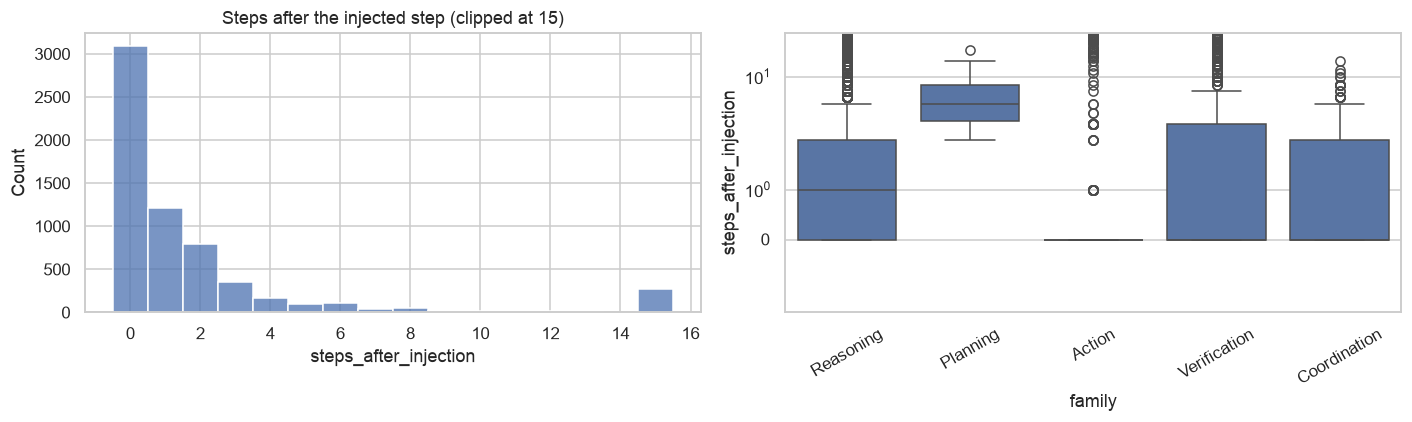

injected step is the LAST step: 3086 (49.4%)


,n,mean,median,share_last_step
framework,,,,
alfagent,311,21.03,23.0,0.00
debate,445,0.54,1.0,0.46
dylan,152,1.41,1.0,0.00
macnet,261,2.58,3.0,0.00
magentic-one,811,1.92,0.0,0.56
mathchat,920,0.62,0.0,0.79
metagpt,81,1.83,2.0,0.00
smolagents,3272,1.11,0.0,0.52


mathchat has the extra field post_injection_turns:


,steps_after_injection
count,920.00
mean,0.62
std,1.93
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,28.00


In [16]:
d = t.dropna(subset=["steps_after_injection"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(d.steps_after_injection.clip(upper=15), discrete=True, ax=ax[0]); ax[0].set_title("Steps after the injected step (clipped at 15)")
sns.boxplot(data=d, x="family", y="steps_after_injection", order=[x for x in FAM_ORDER if x in set(d.family)], ax=ax[1]); ax[1].set_yscale("symlog"); ax[1].tick_params(axis="x", rotation=30)
fig.tight_layout(); save(fig, "C2_steps_after_injection")
print("injected step is the LAST step:", (d.steps_after_injection==0).sum(), f"({(d.steps_after_injection==0).mean()*100:.1f}%)")
cs = d.groupby("framework").steps_after_injection.agg(["count","mean","median",lambda x:(x==0).mean()]).round(2); cs.columns=["n","mean","median","share_last_step"]; display(cs); cs.to_csv(TAB/"C2_cascade_by_framework.csv")
print("mathchat has the extra field post_injection_turns:"); display(t[t.framework=="mathchat"].steps_after_injection.describe().round(2).to_frame())

### C4. Duplicate seeds / repeated tasks
Seed ids are not released; `seed_group` (same framework + same task query) is a proxy. Accuracy estimates from such data are correlated, so cluster bootstrap by seed_group would be needed in Part B.

unique seed groups: 2671 of 6257 traces;  groups with >1 trace: 1686 (63% of groups, covering 84% of traces)


,traces per seed group
count,2671.00
mean,2.34
std,1.41
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,9.00


in repeated groups: mean distinct modes 3.10 (vs size 3.13); same error step repeated in 39% of groups


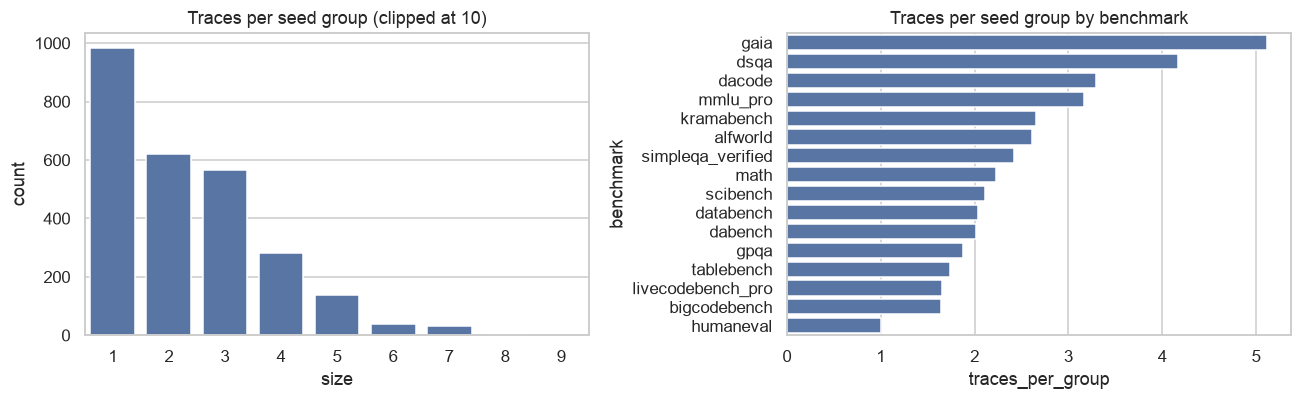

,groups,traces,traces_per_group
benchmark,,,
gaia,59,302,5.12
dsqa,199,830,4.17
dacode,93,306,3.29
mmlu_pro,117,371,3.17
kramabench,31,82,2.65
alfworld,119,311,2.61
simpleqa_verified,210,509,2.42
math,201,448,2.23
scibench,263,555,2.11


In [17]:
g = t.groupby("seed_group").agg(size=("id","size"), n_modes=("gt_mode","nunique"), n_step_labels=("inj_unit_idx","nunique"), framework=("framework","first"), benchmark=("benchmark","first"))
print("unique seed groups:", len(g), "of", len(t), "traces;  groups with >1 trace:", (g['size']>1).sum(), f"({(g['size']>1).mean()*100:.0f}% of groups, covering {t.seed_group.map(g['size']).gt(1).mean()*100:.0f}% of traces)")
display(g["size"].describe().round(2).to_frame("traces per seed group"))
multi = g[g["size"]>1]
print(f"in repeated groups: mean distinct modes {multi.n_modes.mean():.2f} (vs size {multi['size'].mean():.2f}); same error step repeated in {(multi.n_step_labels==1).mean()*100:.0f}% of groups")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(x=g["size"].clip(upper=10), ax=ax[0]); ax[0].set_title("Traces per seed group (clipped at 10)")
bs = g.groupby("benchmark").agg(groups=("size","size"), traces=("size","sum")); bs["traces_per_group"]=(bs.traces/bs.groups).round(2); bs = bs.sort_values("traces_per_group", ascending=False)
sns.barplot(x=bs.traces_per_group, y=bs.index, ax=ax[1]); ax[1].set_title("Traces per seed group by benchmark")
fig.tight_layout(); save(fig, "C4_seed_groups"); bs.to_csv(TAB/"C4_seed_groups_by_benchmark.csv"); display(bs)

### C5. Mode applicability audit: which (framework, benchmark) pairs carry each mode?

In [18]:
aud = t.groupby("gt_mode").agg(n=("id","size"), n_frameworks=("framework","nunique"), n_benchmarks=("benchmark","nunique"), n_categories=("task_category","nunique"),
    frameworks=("framework", lambda x: ", ".join(sorted(set(x)))), ).reindex([m for m in MODE_ORDER if m in set(t.gt_mode)])
display(aud); aud.to_csv(TAB/"C5_mode_applicability.csv")
print("Modes seen in only one framework (so mode and framework are not separable):", aud[aud.n_frameworks==1].index.tolist())
pairs = t.groupby(["gt_mode","framework","benchmark"]).size().rename("n").reset_index(); pairs.to_csv(TAB/"C5_mode_framework_benchmark_pairs.csv", index=False)
print("(mode, framework, benchmark) cells observed:", len(pairs), "; with n<30:", (pairs.n<MIN_N).sum())

,n,n_frameworks,n_benchmarks,n_categories,frameworks
gt_mode,,,,,
R.1,621,7,9,4,"alfagent, debate, dylan, macnet, magentic-one,..."
R.2,1089,8,15,5,"alfagent, debate, dylan, macnet, magentic-one,..."
R.3,739,5,10,3,"debate, dylan, macnet, mathchat, smolagents"
R.4,1120,8,16,5,"alfagent, debate, dylan, macnet, magentic-one,..."
PL.1,90,2,3,2,"metagpt, smolagents"
A.1,31,2,2,1,"macnet, metagpt"
A.2,287,2,7,2,"metagpt, smolagents"
A.3,1207,2,5,2,"magentic-one, smolagents"
A.4,53,1,1,1,alfagent


Modes seen in only one framework (so mode and framework are not separable): ['A.4', 'C.1', 'C.2']
(mode, framework, benchmark) cells observed: 109 ; with n<30: 53


### Label ambiguity: alternate accepted answers released with the labels

In [19]:
amb = t[t.n_accepted_alternates>0]
print("traces with accepted alternates:", len(amb), "frameworks:", amb.framework.value_counts().to_dict())
print(amb.gt_mode.value_counts().to_dict())
print("Per the dataset's note these list other (agent, step, mode) readings that are also accepted; for macnet C.3 the canonical label alone is not accepted.")

traces with accepted alternates: 109 frameworks: {'macnet': 109}
{'C.3': 109}
Per the dataset's note these list other (agent, step, mode) readings that are also accepted; for macnet C.3 the canonical label alone is not accepted.


### C1. Is the injected step detectable by style alone?
TF-IDF + logistic regression on the **text of one step** to separate the injected step from the other steps of the same trace (text features only; no position, agent or length features; first 3,000 characters per step). Evaluated with 5-fold CV grouped by `seed_group`.
Baselines: AUC 0.5 and, per trace, the chance of picking the injected step by guessing = mean(1/n_steps).

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score
ss = s[~s.kind.isin(["user","final_answer"])].copy()
ss = ss[ss.trace_id.isin(t.dropna(subset=["inj_unit_idx"]).id)]
ss["y"] = ss.is_decisive_step.astype(int)
ss["seed_group"] = ss.trace_id.map(t.set_index("id").seed_group)
ss["text3k"] = ss.text.str.slice(0, 3000)
print("steps:", len(ss), "positive:", ss.y.sum())
oof = np.zeros(len(ss)); groups = ss.seed_group.values
for tr, te in GroupKFold(5).split(ss, ss.y, groups):
    vec = TfidfVectorizer(min_df=3, max_features=50000, ngram_range=(1,2), sublinear_tf=True)
    Xtr = vec.fit_transform(ss.text3k.iloc[tr]); Xte = vec.transform(ss.text3k.iloc[te])
    clf = LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced").fit(Xtr, ss.y.iloc[tr])
    oof[te] = clf.decision_function(Xte)
ss["score"] = oof
print("overall AUC:", round(roc_auc_score(ss.y, ss.score), 3))
def top1(df): return df.loc[df.score.idxmax(), "y"]
per = ss.groupby("trace_id").apply(lambda df: pd.Series({"hit": top1(df), "chance": 1/len(df), "framework": df.framework.iloc[0], "n": len(df)}))
per = per[per.n>1]
res = per.groupby("framework").agg(n_traces=("hit","size"), top1_acc=("hit","mean"), chance=("chance","mean")).round(3); res["lift"] = (res.top1_acc/res.chance).round(2)
overall = pd.DataFrame({"n_traces":[len(per)], "top1_acc":[per.hit.mean().round(3)], "chance":[per.chance.mean().round(3)], "lift":[round(per.hit.mean()/per.chance.mean(),2)]}, index=["ALL (n_steps>1)"])
res = pd.concat([res, overall]); display(res); res.to_csv(TAB/"C1_style_detectability.csv")
fa = ss.groupby("framework").apply(lambda df: roc_auc_score(df.y, df.score) if df.y.nunique()>1 else np.nan).round(3).to_frame("AUC"); display(fa)

steps: 36030 positive: 6253


overall AUC: 0.976


,n_traces,top1_acc,chance,lift
alfagent,311,0.990,0.033,30.00
debate,445,0.784,0.500,1.57
dylan,152,0.539,0.333,1.62
macnet,261,0.889,0.250,3.56
magentic-one,809,0.807,0.220,3.67
mathchat,920,0.938,0.238,3.94
metagpt,81,0.716,0.333,2.15
smolagents,3272,0.925,0.285,3.25
ALL (n_steps>1),6251,0.892,0.273,3.27


,AUC
framework,
alfagent,1.000
debate,0.715
dylan,0.660
macnet,0.913
magentic-one,0.916
mathchat,0.991
metagpt,0.784
smolagents,0.981


In [21]:
# what words drive the classifier? (fit on all data, report most injected-leaning n-grams)
vec = TfidfVectorizer(min_df=5, max_features=30000, ngram_range=(1,2), sublinear_tf=True)
X = vec.fit_transform(ss.text3k); clf = LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced").fit(X, ss.y)
fn = np.array(vec.get_feature_names_out()); co = clf.coef_[0]
print("most injected-leaning n-grams:", list(fn[np.argsort(-co)[:25]]))
print("most non-injected-leaning n-grams:", list(fn[np.argsort(co)[:15]]))

most injected-leaning n-grams: ['thought ll', 'thought since', 'thought to', 'so', 'since', 'that', 'since the', 'df', 'websurfer', 'll', 'confident', 'websurfer please', 'boxed', 'code web_search', 'am confident', 'yields', 'identified', 'it', 'placement', 'earlier', 'keeps', 'suggestion', 'thought based', 'please', 'logs last']
most non-injected-leaning n-grams: ['code python', 'python', 'python final_answer', 'thought the', 'or', 'need to', 'you', 'the code', 'need', 'search for', 'print df', 'code code', 'thought now', 'next', 'code']


### Extra: trace length (words) vs mode, and error text length

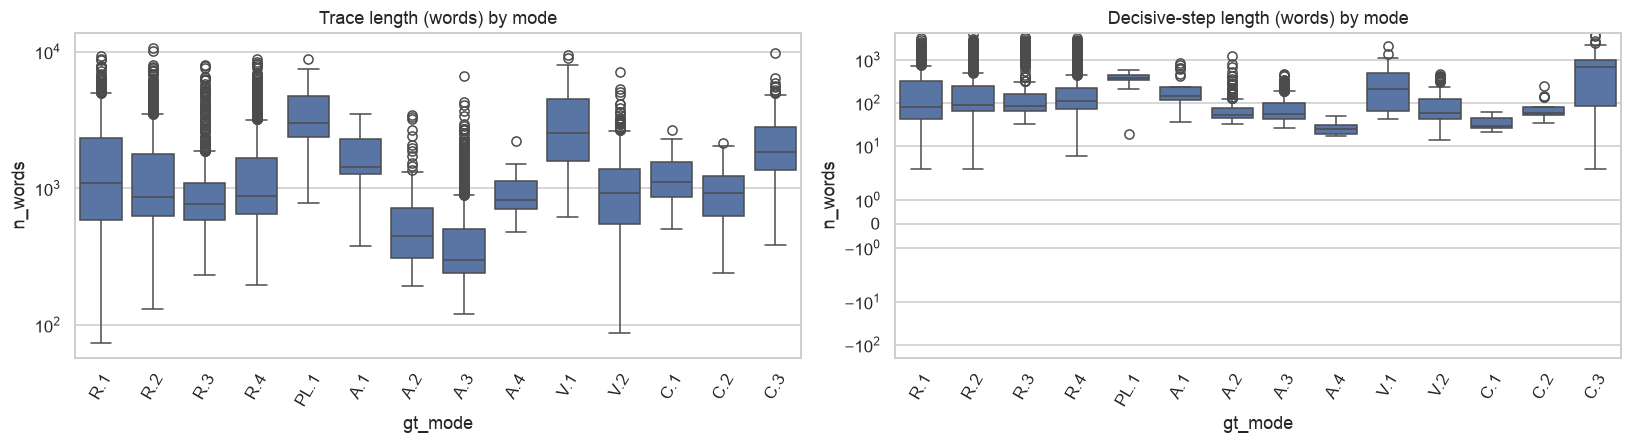

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
mo = [x for x in MODE_ORDER if x in set(t.gt_mode)]
sns.boxplot(data=t, x="gt_mode", y="n_words", order=mo, ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Trace length (words) by mode")
dec = s[s.is_decisive_step].merge(t[["id","gt_mode","framework"]], left_on="trace_id", right_on="id")
sns.boxplot(data=dec, x="gt_mode", y="n_words", order=mo, ax=ax[1]); ax[1].set_yscale("symlog"); ax[1].set_title("Decisive-step length (words) by mode")
for a in ax: a.tick_params(axis="x", rotation=60)
fig.tight_layout(); save(fig, "Extra_length_by_mode")

## Summary of what could not be done here
- **Part B** (LLM attribution runs, hit rates, confusion matrices, symptom-vs-cause) requires model calls and a cost decision; not run.
- **A9** backbone: not released. **A7** modality: constant. Perception modes P.1/P.2 do not occur in the text split.
- **C3, C6-C10** need model runs or the other splits and are out of scope for this notebook.
- Seeds are only approximated (`seed_group`); any CI in Part B should use a cluster bootstrap on it.